<a href="https://colab.research.google.com/github/yorozc/Intro-to-Agent-Based-Modelling/blob/main/intro_to_ABM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Intro to Mesa and Agent-Based Modelling

In [20]:
!pip install mesa

In [21]:
import mesa
print("Mesa version:", mesa.__version__)

Mesa version: 3.5.1


# Recap on Classes

## Class
- Template
- Declare attributes of the class
  - name, age, height, etc.

## Instance
- Filled copy of the template
- Instance
  - Name: jane, Age: 28, Height: 182
- Multiple instances can be created



# How Mesa uses Classes to build a model

## Agent class
```python
Class Citizen(agent):
  citizen name
  citizen id
```

## Model class

```python
# class inherits from model class from Mesa package
Class Country(model):
  country name
  create N citizens (calling class citizen)

# creating model instance
Country(Netherlands)

# creating model with agents
Country(Netherlands, 5 citizens, random name, random id)
```

# What to do with the model

## Agent anatomy
- contains states and rules
- ex: if sick take medicine
  - rules kick in during a certain state
- Performs actions on self
- Performs actions on the environment
  - ex: plant tree
- Performs actions on other agents
  - ex: give another agent money (or basically anything)
- Takes inputs from environment
  - ex: its raining so agent pulls out umbrella
- Takes inputs from other agents
  - ex: change state based on other agents condition and state

# Inheritance
- inheriting attributes and methods from parent/super class

## Super-Class
- Ex: vehicle

## Sub-Class
- Ex: car, motorcycle, bicycle
  - similar attributes but different
  - ex: car has 4 wheels but motorcylcle has 2 but both require wheels.

# Setting up the model

## Create Agent

In [22]:
class MoneyAgent(mesa.Agent):
  """
  Agent with fixed initial wealth
  Class represents an agent in our model. Each agent will have one attribute with its own wealth.
  """


  def __init__(self, model): # passes modele so every agent knows which model it belongs to

    super().__init__(model) # pass world model to get the attr and inits from mesa.Agent parent class

    self.wealth = 1


# Create Model

In [23]:
class MoneyModel(mesa.Model):
  """
  A model with some number of agents.
  Represents overall model/environment where agents will populate
  """

  def __init__(self, N):
    super().__init__()

    # initialize the model with N agents
    self.num_agents = N

    # create agents and add them to model

    for i in range(self.num_agents):
      a = MoneyAgent(self)

      # add agent to model




# Adding agents actions and step method


In [28]:
import matplotlib.pyplot as plt

class MoneyAgent(mesa.Agent):
  """
  Agent with fixed initial wealth
  Class represents an agent in our model. Each agent will have one attribute with its own wealth.
  """


  def __init__(self, model): # passes modele so every agent knows which model it belongs to

    super().__init__(model) # pass world model to get the attr and inits from mesa.Agent parent class
    self.wealth = 1

  def step(self):
    """
    Define the actions the agent takes in one step.
    Here, the agent will simply print its unique identifier.
    """

    print("Hi, I am agent " + str(self.unique_id) + ".") # unique_id built-in attr of mesa.Agent to track Agent IDs


class MoneyModel(mesa.Model):

  def __init__(self, N):
    super().__init__()
    self.num_agents = N

    for i in range(self.num_agents):
      a = MoneyAgent(self)

  def step(self):
    """
    advance model by one step
    each step, every agent's 'step' method will be called
    """

    # self.agents.shuffle_do("step")
    # self.agents.do("step")
    self.agents.shuffle_do("step") # trigger all agents in random order to take a step


In [29]:
# create a model instance with 10 agents
empty_model = MoneyModel(10)

empty_model.step()


Hi, I am agent 4.
Hi, I am agent 5.
Hi, I am agent 7.
Hi, I am agent 1.
Hi, I am agent 8.
Hi, I am agent 2.
Hi, I am agent 6.
Hi, I am agent 3.
Hi, I am agent 10.
Hi, I am agent 9.


# Random Seed for Reproducibility
- in newer versions seed has been deprecated
- use 'rng' instead

In [32]:
class MoneyModel(mesa.Model):
  """
  A model with some number of agents.
  Represents overall model/environment where agents will populate
  """

  def __init__(self, N, rng=None):
    super().__init__(rng=rng)

    # initialize the model with N agents
    self.num_agents = N

    # create agents and add them to model

    for i in range(self.num_agents):
      a = MoneyAgent(self)

  def step(self):
    """
    advance the model by one step
    each step, every agent's step method will be called
    """
    self.agents.shuffle_do("step")

In [41]:
empty_model = MoneyModel(10, rng=123)

empty_model.step()

Hi, I am agent 9.
Hi, I am agent 8.
Hi, I am agent 6.
Hi, I am agent 10.
Hi, I am agent 3.
Hi, I am agent 4.
Hi, I am agent 7.
Hi, I am agent 2.
Hi, I am agent 5.
Hi, I am agent 1.


In [43]:
empty_model.step() # 2 steps done

Hi, I am agent 2.
Hi, I am agent 9.
Hi, I am agent 6.
Hi, I am agent 7.
Hi, I am agent 5.
Hi, I am agent 8.
Hi, I am agent 10.
Hi, I am agent 1.
Hi, I am agent 3.
Hi, I am agent 4.


# Agent/Model Behavior

change behavior of agent to where each agent gives 1 wealth to a random agent if their wealth is greater than 0. Run a few steps of the model to see how the agent activation order is shuffled each step.

In [44]:
class MoneyAgent(mesa.Agent):

  def __init__(self, model):
    super().__init__(model)
    self.wealth = 1

  # agent-based behavior
  def step(self):
    if self.wealth == 0:
      return # no wealth, do nothing
    other_agent = self.random.choice(self.model.agents) # choose other agent at random
    other_agent.wealth += 1 # give 1 wealth to that random agent
    self.wealth -= 1 # current instance of agent loses 1 wealth


## Running model

In [59]:
model = MoneyModel(10)

for _ in range(10):
  model.step()

In [46]:
%matplotlib inline

[0, 4, 1, 1, 2, 1, 0, 1, 0, 0]


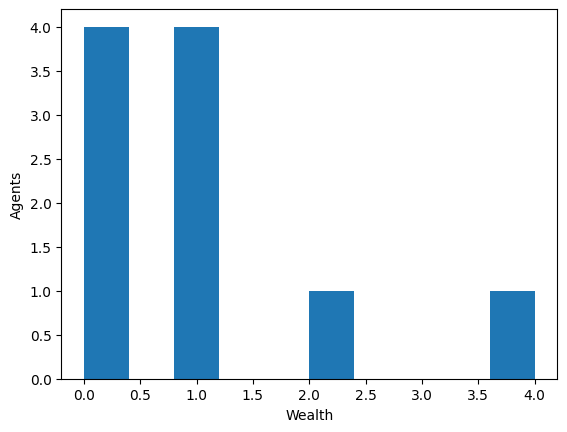

In [62]:
agent_wealth = [a.wealth for a in model.agents] # create list of each agents wealth
print(agent_wealth)
plt.hist(agent_wealth)
plt.xlabel("Wealth")
plt.ylabel("Agents")
plt.show()

# Model Behavior


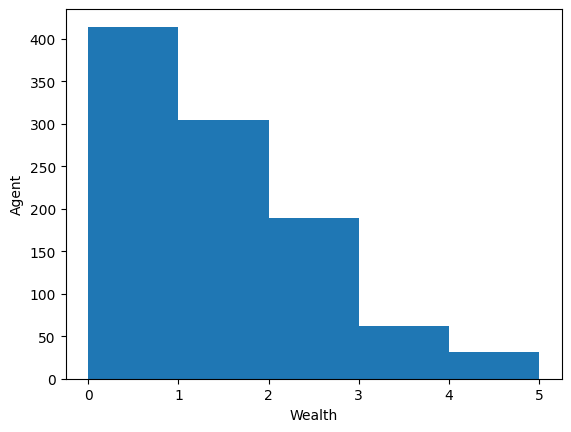

In [70]:
all_wealth = [] # list used to store wealth data

# run the ten steps 100 times (1000 results but each 10 are different model's results)
for i in range(100):
  model = MoneyModel(10)
  for j in range(10):
    model.step()

  for agent in model.agents:
    all_wealth.append(agent.wealth)


# get largest wealth amount and add 1 due to range creating bins based off of zero indexing
plt.hist(all_wealth, bins=range(max(all_wealth) + 1))
plt.xlabel("Wealth")
plt.ylabel("Agent")
plt.show()

# Mesa Spaces
- SingleGrid and Multigrid

## SingleGrid:
- at most one agent per cell

## MultiGrid:
- multiple agents are allowed within the same cell

- All of our agents are to share a world so MultiGrid will be used


In [72]:
class MoneyModel(mesa.Model):

  def __init__(self, N, width, height):
    super().__init__()
    self.num_agents = N
    self.grid = mesa.space.MultiGrid(width, height, torus=True)
    # torus=True makes grid wrap around

    # create agents and place them on the grid
    for i in range(self.num_agents):
      a = MoneyAgent(self)

      # add agent to random grid cell
      x = self.random.randrange(self.grid.width)
      y = self.random.randrange(self.grid.height)
      self.grid.place_agent(a, (x, y)) # place agent at coordinates (x, y)

# Moving Agents

# move() function
- using .get_neighborhood()
  - returns list of cells that are in the neighborhood
  - will be used as possible steps for agent
  - moore=True & include_center=False will lead to the agent being able to move at most with a radius of 8

- choose randomly from the list .get_neighborhood() returns


In [74]:
class MoneyAgent(mesa.Agent):
  def __init__(self, model):
    super().__init__(model)
    self.wealth = 1

  # agent-based behavior
  def step(self):
    if self.wealth == 0:
      return # no wealth, do nothing
    other_agent = self.random.choice(self.model.agents) # choose other agent at random
    other_agent.wealth += 1 # give 1 wealth to that random agent
    self.wealth -= 1 # current instance of agent loses 1 wealth

  def move(self):
    possible_steps = self.model.grid.get_neighborhood(
        self.pos, # current position of agent
        moore=True, # Moore neighborhood (includes diagonals)
        include_center=False # Exclude the cell where the agent is currently located
    )

    new_position = self.random.choice(possible_steps) # choose new position at random
    self.model.grid.move_agent(self, new_position)


give money to one of the agents present at the same cell

In [76]:
class MoneyAgent(mesa.Agent):
  def __init__(self, model):
    super().__init__(model)
    self.wealth = 1

  # agent-based behavior
  def step(self):
    if self.wealth == 0:
      return # no wealth, do nothing
    other_agent = self.random.choice(self.model.agents) # choose other agent at random
    other_agent.wealth += 1 # give 1 wealth to that random agent
    self.wealth -= 1 # current instance of agent loses 1 wealth

  def move(self):
    possible_steps = self.model.grid.get_neighborhood(
        self.pos, # current position of agent
        moore=True, # Moore neighborhood (includes diagonals)
        include_center=False # Exclude the cell where the agent is currently located
    )

    new_position = self.random.choice(possible_steps) # choose new position at random
    self.model.grid.move_agent(self, new_position)

  def give_money(self):
    # get all agents in the same cell as the current agent
    cellmates = self.model.grid.get_cell_list_contents([self.pos])

    if len(cellmates) > 1:
      other = self.random.choice(cellmates) # randomly select agent in the same cell
      if other != self: # check to make sure the selected agent is not itself
        other.wealth += 1
        self.wealth -= 1

agent step method will change

In [77]:
class MoneyAgent(mesa.Agent):
  def __init__(self, model):
    super().__init__(model)
    self.wealth = 1

  # agent-based behavior
  def step(self):
    self.move() # First the agent moves to a new position
    if self.wealth > 0:
      self.give_money() # if agent has wealth, give to other agent in same cell

  def move(self):
    possible_steps = self.model.grid.get_neighborhood(
        self.pos, # current position of agent
        moore=True, # Moore neighborhood (includes diagonals)
        include_center=False # Exclude the cell where the agent is currently located
    )

    new_position = self.random.choice(possible_steps) # choose new position at random
    self.model.grid.move_agent(self, new_position)

  def give_money(self):
    # get all agents in the same cell as the current agent
    cellmates = self.model.grid.get_cell_list_contents([self.pos])

    if len(cellmates) > 1:
      other = self.random.choice(cellmates) # randomly select agent in the same cell
      if other != self: # check to make sure the selected agent is not itself
        other.wealth += 1
        self.wealth -= 1

Create model with 50 agents, 10x10 grid, and run it for 20 steps

In [82]:
model = MoneyModel(50, 10, 10)
STEPS = 20
for i in range(STEPS):
  model.step()

Visualization below

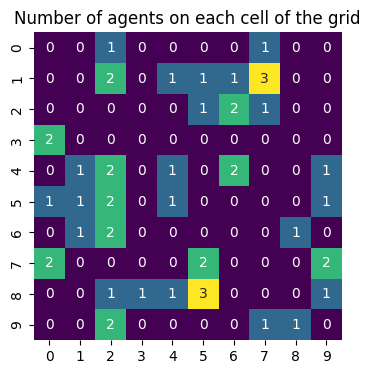

In [83]:
import seaborn as sns
import numpy as np

agent_counts = np.zeros((model.grid.width, model.grid.height))
for cell_content, (x, y) in model.grid.coord_iter():
  agent_count = len(cell_content)
  agent_counts[x][y] = agent_count

g = sns.heatmap(agent_counts, cmap="viridis", annot=True, cbar=False, square=True)
g.figure.set_size_inches(4,4)
g.set(title="Number of agents on each cell of the grid")
plt.show()


# Collecting Data
- DataCollector object allows us to collect data from the model

## Agent Level
- Collect every agent's wealth at every step

## Model Level
- Measure the model's Gini Coefficient
  - Gini Coefficient: measure of wealth inequality

## Gini Coefficient
- statistical measure of economic inequality that quantifies the dispersion of income or wealth across a population

In [84]:
def compute_gini(model):
  agent_wealths = [agent.wealth for agent in model.agents]
  x = sorted(agent_wealths) # sort wealth values
  N = model.num_agents # num of agents
  # calculate the B index as part of the Gini formula
  B = sum(xi * (N - i) for i, xi in enumerate(x)) / (N * sum(x))
  return 1 + (1 / N) - 2 * B # compute and return Gini Coefficient

In [87]:
class MoneyModel(mesa.Model):

  def __init__(self, N, width, height):
    super().__init__()
    self.num_agents = N
    self.grid = mesa.space.MultiGrid(width, height, torus=True)
    # torus=True makes grid wrap around

    # create agents and place them on the grid
    for i in range(self.num_agents):
      a = MoneyAgent(self)

      # add agent to random grid cell
      x = self.random.randrange(self.grid.width)
      y = self.random.randrange(self.grid.height)
      self.grid.place_agent(a, (x, y)) # place agent at coordinates (x, y)

    # init DataCollector
    self.datacollector = mesa.DataCollector(
        model_reporters={"Gini": compute_gini}, # model-level data: Gini coefficient
        agent_reporters={"Wealth": "wealth"}   # agent-level data: wealth of each agent
    )

    # Collect data at step 0 (initial state of the model)
    self.datacollector.collect(self)

  def step(self):
    self.agents.shuffle_do("step") # randomly activate each agent
    self.datacollector.collect(self) # collect data after the step

In [88]:
model = MoneyModel(10, 10, 10)

for i in range(100):
  model.step()

In [94]:
gini = model.datacollector.get_model_vars_dataframe() # retrieves Gini coefficient data for each step
gini

,Gini
0,0.00
1,0.18
2,0.18
3,0.18
4,0.18
...,...
96,0.54
97,0.64
98,0.64
99,0.64


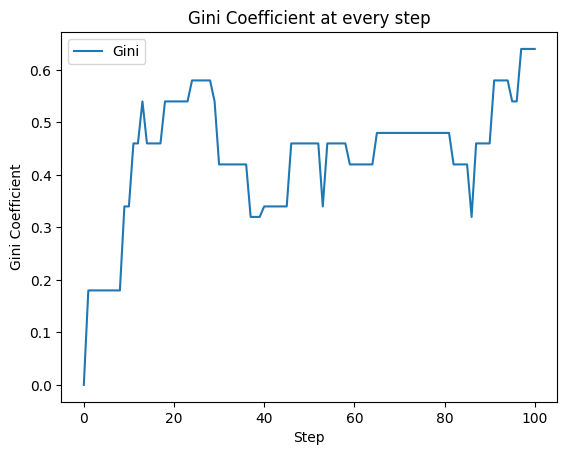

In [98]:
gini.plot() # plots gini coefficient over time
plt.xlabel("Step")
plt.ylabel("Gini Coefficient")
plt.title("Gini Coefficient at every step")
plt.show()

In [110]:
agent_wealth = model.datacollector.get_agent_vars_dataframe()
agent_wealth.loc[100]

,Wealth
AgentID,
1,0
2,1
3,0
4,2
5,0
6,0
7,4
8,2
9,0


In [113]:
agent_wealth.loc[0]

,Wealth
AgentID,
1,1
2,1
3,1
4,1
5,1
6,1
7,1
8,1
9,1


# Visualization

# Batch Runner